# Part 1 — both efficiency changes combined

Same **simple recipe** as `submission/part1_simple.ipynb`, same 320px data. **Two changes**, each validated
separately in `part1_narrow_stem.ipynb` and `part1_blocks_2221.ipynb`:

| change | what it targets | effect |
|---|---|---|
| `stem_channels = (32, 32, 64)` | the three stem convolutions run at 160x160, where FLOPs are dominated by the spatial size | ~9.0 -> ~1.5 GFLOPs |
| `blocks_per_stage = (2, 2, 2, 1)` | the last 1280->1280 block is ~40% of the weights and sits on a 10x10 map | 7.7M -> ~4.6M params |

Together: roughly **2.5x less compute and 1.7x fewer parameters** than the baseline. The cell below prints
parameters and GFLOPs for all four combinations, so the claim is measured, not assumed.

### About the number of epochs

Training accuracy reaches ~1.0 around epoch 40-45, which is *not* a reason to stop: in every run so far the
validation loss kept falling well past that point, and validation accuracy kept climbing.

| run | train acc = 1.0 at | val acc then | val acc at the end |
|---|---|---|---|
| simple, 224px | ~epoch 50 | ~56% | **64.9%** (epoch 140) |
| cosine + EMA, 320px | ~epoch 51 | 58.0% | **67.7%** (epoch 146) |

So `epochs` stays at 150 here, and the speedup comes from the architecture rather than from a shorter schedule.
The signal that would justify stopping early is the **validation loss flattening or turning upward** — watch that
curve, not the training accuracy.

## The dataset

FGVC-Aircraft labels every image at three levels of a hierarchy: **manufacturer** (e.g. Boeing), **family**
(e.g. Boeing 737) and **variant** (e.g. Boeing 737-700). We use `annotation_level="variant"`, the finest level of
the benchmark, which `torchvision` exposes as **100 classes** (the dataset page counts 102 variants in total).

A variant deliberately *collapses all the models that are visually indistinguishable into one class*, so the task
is well posed: every class can in principle be told apart from the image alone. The difficulty is therefore not
label ambiguity but

* **very little data**: 3,334 training / 3,333 validation / 3,333 test images, i.e. only **~33 training images per
  class**, so the network memorizes the training set long before it runs out of things to learn;
* **subtle, localized evidence**: variants of the same family differ by engine type, winglets, window or door
  layout — details that survive a resize to 320px far better than to 224px.

Every image also carries a ~20 pixel copyright banner at the bottom ("Photo by ... / Airliners.net"). We crop it
away, otherwise the network could pick up photographer-specific cues instead of aircraft shape. The crop is
deterministic and applied to all three splits; normalization statistics are computed on the **training split
only**, so no information leaks from validation or test.

## Import dependencies

In [12]:
import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sn

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.notebook import tqdm

from torch.utils.data import DataLoader
from torchvision import transforms as T, datasets

## Reproducibility and runtime

As in the lab sessions, we disable every source of randomness we can control, so that the comparison between
different configurations is not polluted by run-to-run variance.

In [13]:
def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(42)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {device}")

Device: cuda


## Data

Training images get light augmentation (horizontal flip, small rotation, colour jitter). Validation and test
images are only resized and normalized: their transform is deterministic, identical for every image, and uses
statistics computed on the training split.

In [14]:
img_size = 320      # fine-grained details survive this resize much better than 224
batch_size = 64
epochs = 70
n_classes = 100
stem_channels = (32, 32, 64)      # change 1: was (80, 80, 160), tied to stage_channels[0] // 2
blocks_per_stage = (2, 2, 2, 1)   # change 2: was (2, 2, 2, 2); the last 1280->1280 block was ~40% of the weights

# channel statistics computed on the training split only
mean = (0.488, 0.519, 0.544)
std = (0.211, 0.203, 0.236)


class RemoveBanner:
    """Crop the ~20 pixel copyright banner at the bottom of every FGVC-Aircraft image."""

    def __call__(self, img):
        return img.crop((0, 0, img.width, img.height - 20))

In [15]:
tsfms_train = T.Compose([
    RemoveBanner(),
    T.Resize((img_size, img_size)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean, std)
])

tsfms_eval = T.Compose([
    RemoveBanner(),
    T.Resize((img_size, img_size)),
    T.ToTensor(),
    T.Normalize(mean, std)
])

In [16]:
train_dset = datasets.FGVCAircraft(
    root="./data",
    split="train",
    annotation_level="variant",
    transform=tsfms_train,
    download=True
)
val_dset = datasets.FGVCAircraft(
    root="./data",
    split="val",
    annotation_level="variant",
    transform=tsfms_eval,
    download=True
)
test_dset = datasets.FGVCAircraft(
    root="./data",
    split="test",
    annotation_level="variant",
    transform=tsfms_eval,
    download=True
)

train_dl = DataLoader(
    train_dset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    drop_last=True      # avoids a tiny last batch, which would make BatchNorm statistics noisy
)
val_dl = DataLoader(val_dset, batch_size=128, num_workers=8)
test_dl = DataLoader(test_dset, batch_size=128, num_workers=8)

print(f"Classes: {len(train_dset.classes)}")
print(f"Train: {len(train_dset)} - Validation: {len(val_dset)} - Test: {len(test_dset)}")

Classes: 100
Train: 3334 - Validation: 3333 - Test: 3333


A batch of training images, after augmentation:

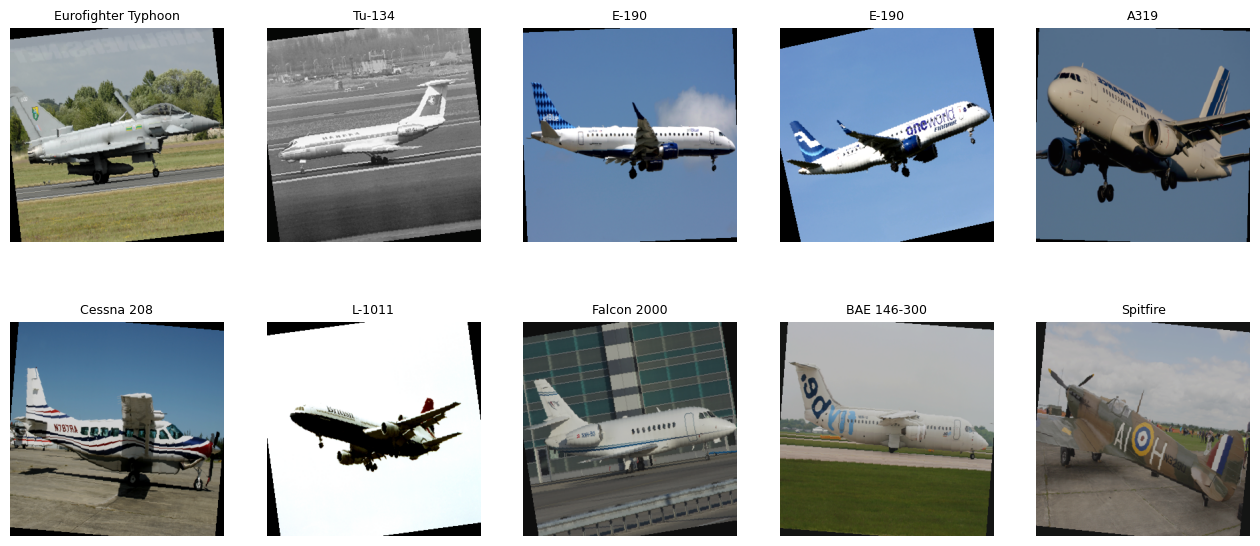

In [17]:
imgs, labels = next(iter(train_dl))

_, ax = plt.subplots(2, 5, figsize=(16, 7))

for i, a in enumerate(ax.flat):
    img = imgs[i].permute(1, 2, 0) * torch.tensor(std) + torch.tensor(mean)
    a.imshow(img.clamp(0, 1))
    a.set_title(train_dset.classes[labels[i]], fontsize=9)
    a.axis("off")

## The network

We arrived at this design by starting from a plain stack of convolutions and fixing one measured problem at a time:

1. **A plain CNN memorizes immediately** (training accuracy ~100%, validation ~21%), so generalization — not
   capacity — is the hard part.
2. **Global average pooling instead of flatten + fully connected.** In the plain CNN, 81% of all parameters sat in
   the first linear layer, which is where memorization happens. Averaging the spatial dimensions away removes them
   (Lin et al., *Network in Network*, ICLR 2014; used by GoogLeNet and ResNet).
3. **Batch Normalization after every convolution** (Ioffe & Szegedy, ICML 2015): without it the deeper network did
   not train at all in our experiments.
4. **Multi-branch blocks.** The evidence that separates two variants lives at several scales at once — overall
   fuselage proportions, but also engine, winglet and window detail. A block that applies 1x1, 3x3 and (factorized)
   5x5 convolutions *in parallel* and concatenates the results lets every layer pick its own scale, instead of
   committing to a single receptive field. The leading 1x1 convolutions reduce the channel count first, which keeps
   the block cheap (Szegedy et al., *Going Deeper with Convolutions*, CVPR 2015).
5. **A stem that downsamples early**, so the expensive blocks run on smaller feature maps.

The two changes tested in this notebook follow from where the cost actually sits — parameters do not depend on the
spatial size, FLOPs do:

6. **A narrow stem** (`3 -> 32 -> 32 -> 64`). Its convolutions run at 160x160, so with the previous widths
   (`80 -> 80 -> 160`) they consumed ~9 of the ~13.4 GFLOPs of the whole network while holding only ~2% of the
   parameters. ResNet-C uses `32 -> 32 -> 64` here, GoogLeNet `64 -> 64 -> 192`.
7. **One block in the last stage** instead of two. The second 1280->1280 block held ~40% of all weights and ran on
   a 10x10 map, where four stride-2 reductions have already made each unit's receptive field cover most of the
   aircraft: it added capacity, not context.

The resulting network: each stage halves the spatial resolution and doubles the width.

```
stem        3x3 s2 (32) -> 3x3 (32) -> 3x3 (64) -> maxpool s2     320 -> 80,  64 ch
stage 1     2 inception blocks, 160 channels                       80x80
stage 2     2 inception blocks, 320 channels                       40x40
stage 3     2 inception blocks, 640 channels                       20x20
stage 4     1 inception block,  1280 channels                      10x10
head        global average pool -> dropout -> linear(1280, 100)
```

The cell below prints parameters and GFLOPs for this configuration and for the three it is compared against.

In [18]:
def get_conv_bn(in_channels: int, out_channels: int, kernel_size: int, stride: int = 1) -> nn.Sequential:
    """Return a Sequential block with a convolution followed by Batch Normalization.

    The convolution has no bias, since the Batch Normalization that follows it would cancel it out.

    Args:
        in_channels: number of input channels.
        out_channels: number of output channels.
        kernel_size: size of the (square) kernel.
        stride: stride of the convolution.

    Returns: the created Sequential block.
    """
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride,
                  padding=kernel_size // 2, bias=False),
        nn.BatchNorm2d(out_channels)
    )


class InceptionBlock(nn.Module):
    """Four parallel branches, concatenated along the channel dimension:

        1x1                     pointwise
        1x1 -> 3x3              medium receptive field
        1x1 -> 3x3 -> 3x3       5x5 receptive field, factorized into two 3x3
        maxpool -> 1x1          pooled view of the input

    The leading 1x1 convolutions reduce the number of channels before the expensive 3x3 ones.
    """

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        quarter = out_channels // 4
        reduced = max(out_channels // 8, 8)

        self.branch_1x1 = get_conv_bn(in_channels, quarter, 1, stride)

        self.branch_3x3 = nn.Sequential(
            get_conv_bn(in_channels, reduced, 1), nn.ReLU(),
            get_conv_bn(reduced, quarter, 3, stride)
        )

        self.branch_5x5 = nn.Sequential(
            get_conv_bn(in_channels, reduced, 1), nn.ReLU(),
            get_conv_bn(reduced, quarter, 3), nn.ReLU(),
            get_conv_bn(quarter, quarter, 3, stride)
        )

        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(3, stride=stride, padding=1),
            get_conv_bn(in_channels, out_channels - 3 * quarter, 1)
        )

    def forward(self, x):
        branches = [self.branch_1x1(x), self.branch_3x3(x), self.branch_5x5(x), self.branch_pool(x)]
        return F.relu(torch.cat(branches, dim=1))


class AircraftNet(nn.Module):
    """Stem, four stages of Inception blocks, global average pooling, linear classifier."""

    def __init__(self, n_classes, channels=(160, 320, 640, 1280), stem_channels=(32, 32, 64),
                 blocks_per_stage=(2, 2, 2, 1), dropout=0.0):
        """stem_channels sets the three stem convolutions; blocks_per_stage is an int or one value per stage."""
        super().__init__()
        c1, c2, c3 = stem_channels
        if isinstance(blocks_per_stage, int):
            blocks_per_stage = (blocks_per_stage,) * len(channels)

        # The stem reduces 320x320 to 80x80 before the expensive blocks. Its width is kept small on purpose:
        # these convolutions run at 160x160, where the cost is dominated by the spatial size rather than by the
        # number of channels. ResNet-C uses 32 -> 32 -> 64 here, GoogLeNet 64 -> 64 -> 192.
        self.stem = nn.Sequential(
            get_conv_bn(3, c1, 3, stride=2), nn.ReLU(),
            get_conv_bn(c1, c2, 3), nn.ReLU(),
            get_conv_bn(c2, c3, 3), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1)
        )

        blocks = []
        in_channels = c3
        for stage, (out_channels, n_blocks) in enumerate(zip(channels, blocks_per_stage)):
            for block in range(n_blocks):
                # the first block of every stage (except the first one) halves the resolution
                stride = 2 if (block == 0 and stage > 0) else 1
                blocks.append(InceptionBlock(in_channels, out_channels, stride))
                in_channels = out_channels
        self.stages = nn.ModuleList(blocks)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),    # global average pooling
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(in_channels, n_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        for block in self.stages:
            x = block(x)
        return self.head(x)


def count_conv_flops(model, img_size: int) -> float:
    """Count the multiply-add FLOPs of all convolutions for one image, using forward hooks.

    The FLOPs of a convolution are 2 * C_out * H_out * W_out * C_in * K * K (lecture 4): they grow with
    the *spatial* size of the output, unlike the parameter count, which does not depend on it at all.

    Args:
        model: the network (or a submodule of it).
        img_size: side of the (square) input image.

    Returns: the number of FLOPs, in billions.
    """
    total = []

    def hook(module, inputs, output):
        c_in = module.in_channels // module.groups
        k = module.kernel_size[0] * module.kernel_size[1]
        total.append(2 * output.shape[1] * output.shape[2] * output.shape[3] * c_in * k)

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, nn.Conv2d)]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, img_size, img_size, device=next(model.parameters()).device))
    for h in handles:
        h.remove()
    return sum(total) / 1e9


model = AircraftNet(n_classes, stem_channels=stem_channels, blocks_per_stage=blocks_per_stage).to(device)

configs = [
    ("baseline  (80,80,160) + (2,2,2,2)", (80, 80, 160), 2),
    ("narrow stem only                 ", (32, 32, 64), 2),
    ("7 blocks only                    ", (80, 80, 160), (2, 2, 2, 1)),
    ("this run: both                   ", stem_channels, blocks_per_stage),
]

print(f"{'configuration':36s} {'params':>10s} {'GFLOPs':>8s}")
for name, stem, blocks in configs:
    m = AircraftNet(n_classes, stem_channels=stem, blocks_per_stage=blocks).to(device)
    print(f"{name:36s} {sum(p.numel() for p in m.parameters()):10,d} "
          f"{count_conv_flops(m, img_size):8.1f}")
    del m

configuration                            params   GFLOPs
baseline  (80,80,160) + (2,2,2,2)     7,671,700     14.7
narrow stem only                      7,513,348      7.1
7 blocks only                         4,595,860     14.1
this run: both                        4,437,508      6.4


## Optimization

Adam with a constant learning rate of 2e-4 and cross-entropy with a small amount of label smoothing. Nothing
else: no learning-rate schedule, no weight decay, no dropout.

In [19]:
opt = torch.optim.Adam(model.parameters(), lr=2e-4)
label_smoothing = 0.05

def ncorrect(scores, y):
    y_hat = torch.argmax(scores, -1)
    return (y_hat == y).sum()


def accuracy(scores, y):
    correct = ncorrect(scores, y)
    return correct.true_divide(y.shape[0])

In [20]:
def train_loop(model, train_dl, epochs, opt, val_dl=None, verbose=False):
    """Train the model, keeping the parameters that performed best on the validation set.

    Args:
        model: the network to train.
        train_dl: data loader of the training set.
        epochs: number of epochs.
        opt: the optimizer.
        val_dl: data loader of the validation set.
        verbose: whether to print the metrics during training.

    Returns: the best validation accuracy, the corresponding parameters, the epoch they come from,
        and the per-epoch history.
    """
    best_val_acc = 0
    best_params = []
    best_epoch = -1
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for e in tqdm(range(epochs)):
        # Train
        model.train()
        train_loss = 0
        train_samples = 0
        train_acc = 0
        for train_data in train_dl:
            imgs = train_data[0].to(device)
            labels = train_data[1].to(device)
            scores = model(imgs)
            loss = F.cross_entropy(scores, labels, label_smoothing=label_smoothing)
            train_loss += loss.item() * imgs.shape[0]
            train_samples += imgs.shape[0]
            train_acc += ncorrect(scores, labels).item()

            opt.zero_grad()  # clear
            loss.backward()  # fill
            opt.step()       # use

        train_acc /= train_samples
        train_loss /= train_samples

        # Validation
        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_samples = 0
            val_acc = 0
            for val_data in val_dl:
                imgs = val_data[0].to(device)
                labels = val_data[1].to(device)
                val_scores = model(imgs)
                val_loss += F.cross_entropy(val_scores, labels).item() * imgs.shape[0]
                val_samples += imgs.shape[0]
                val_acc += ncorrect(val_scores, labels).item()
            val_acc /= val_samples
            val_loss /= val_samples

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_params = copy.deepcopy(model.state_dict())
                torch.save(best_params, "best_model_small.pth")
                best_epoch = e

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose and e % 5 == 0:
            print(f"Epoch {e}: train loss {train_loss:.3f} - train acc {train_acc:.3f}"
                  f" - valid loss {val_loss:.3f} - valid acc {val_acc:.3f}")

    if verbose:
        print(f"Best epoch {best_epoch}, best acc {best_val_acc:.3f}")

    return best_val_acc, best_params, best_epoch, history

## Training

In [21]:
start_time = time.time()

best_val_acc, best_params, best_epoch, history = train_loop(
    model,
    train_dl,
    epochs,
    opt,
    val_dl,
    verbose=True
)

print(f"Training time: {(time.time() - start_time) / 60:.0f} min")

  0%|          | 0/70 [00:00<?, ?it/s]

Epoch 0: train loss 4.580 - train acc 0.020 - valid loss 4.490 - valid acc 0.027
Epoch 5: train loss 3.779 - train acc 0.125 - valid loss 3.857 - valid acc 0.096
Epoch 10: train loss 3.022 - train acc 0.266 - valid loss 3.088 - valid acc 0.183
Epoch 15: train loss 2.554 - train acc 0.391 - valid loss 2.810 - valid acc 0.246
Epoch 20: train loss 2.123 - train acc 0.518 - valid loss 2.553 - valid acc 0.300
Epoch 25: train loss 1.699 - train acc 0.663 - valid loss 2.397 - valid acc 0.370
Epoch 30: train loss 1.393 - train acc 0.758 - valid loss 2.538 - valid acc 0.339
Epoch 35: train loss 1.117 - train acc 0.856 - valid loss 2.336 - valid acc 0.401
Epoch 40: train loss 0.900 - train acc 0.931 - valid loss 2.165 - valid acc 0.458
Epoch 45: train loss 0.779 - train acc 0.959 - valid loss 2.230 - valid acc 0.453
Epoch 50: train loss 0.689 - train acc 0.977 - valid loss 2.311 - valid acc 0.453
Epoch 55: train loss 0.627 - train acc 0.987 - valid loss 2.129 - valid acc 0.475
Epoch 60: train lo

## Results

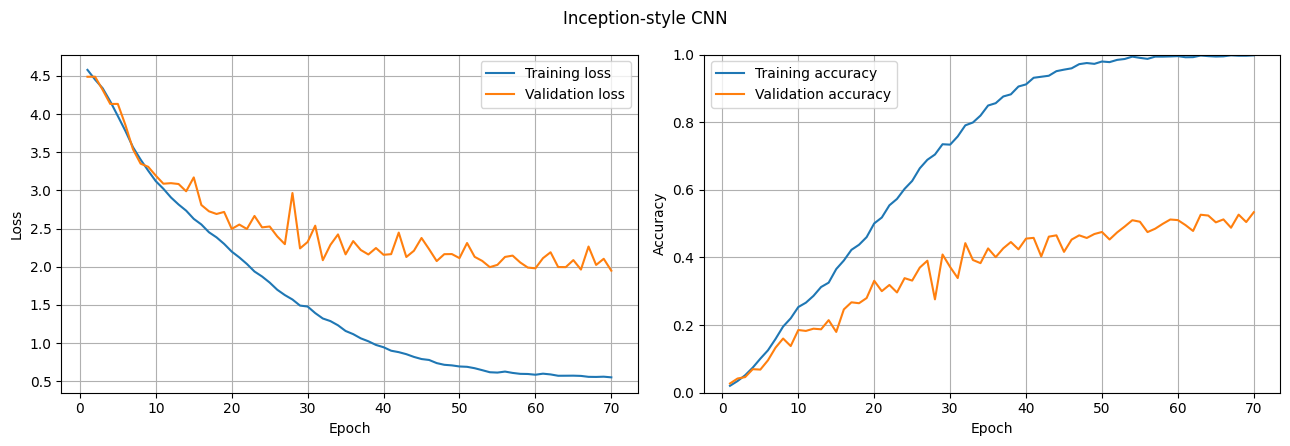

In [22]:
def plot_history(history: dict, title: str) -> None:
    """Plot the loss and the accuracy recorded at every epoch.

    Args:
        history: dictionary of per-epoch lists, as returned by train_loop.
        title: title of the figure.
    """
    epochs_range = range(1, len(history["train_loss"]) + 1)
    _, ax = plt.subplots(1, 2, figsize=(13, 4.5))

    ax[0].plot(epochs_range, history["train_loss"], label="Training loss")
    ax[0].plot(epochs_range, history["val_loss"], label="Validation loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].grid(True); ax[0].legend()

    ax[1].plot(epochs_range, history["train_acc"], label="Training accuracy")
    ax[1].plot(epochs_range, history["val_acc"], label="Validation accuracy")
    if "ema_acc" in history:
        ax[1].plot(epochs_range, history["ema_acc"], label="Validation accuracy (EMA)")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_ylim(0, 1)
    ax[1].grid(True); ax[1].legend()

    plt.suptitle(title); plt.tight_layout(); plt.show()


plot_history(history, "Inception-style CNN")

## Test set

The test split is used **once**, on the final model. Every design decision above was taken on the validation
split only.

In [23]:
model.load_state_dict(best_params)
model.eval()

test_loss = test_samples = test_correct = 0
confusion_matrix = torch.zeros(n_classes, n_classes, dtype=torch.int)

with torch.no_grad():
    for test_data in tqdm(test_dl):
        imgs = test_data[0].to(device)
        labels = test_data[1].to(device)
        scores = model(imgs)

        test_loss += F.cross_entropy(scores, labels).item() * imgs.shape[0]
        test_samples += imgs.shape[0]
        test_correct += ncorrect(scores, labels).item()

        for label, prediction in zip(labels, torch.argmax(scores, -1)):
            confusion_matrix[label, prediction] += 1

test_acc = test_correct / test_samples
print(f"Test - loss: {test_loss / test_samples:.4f}, accuracy: {test_acc:.3f}")

  0%|          | 0/27 [00:00<?, ?it/s]

Test - loss: 1.9116, accuracy: 0.540


### Confusion matrix

As in Lab Session 4, we also compute the confusion matrix, and recompute the accuracy from it as a sanity check.
The most frequent confusions are informative: they are almost always *within the same family*.

Accuracy from the confusion matrix: 0.540


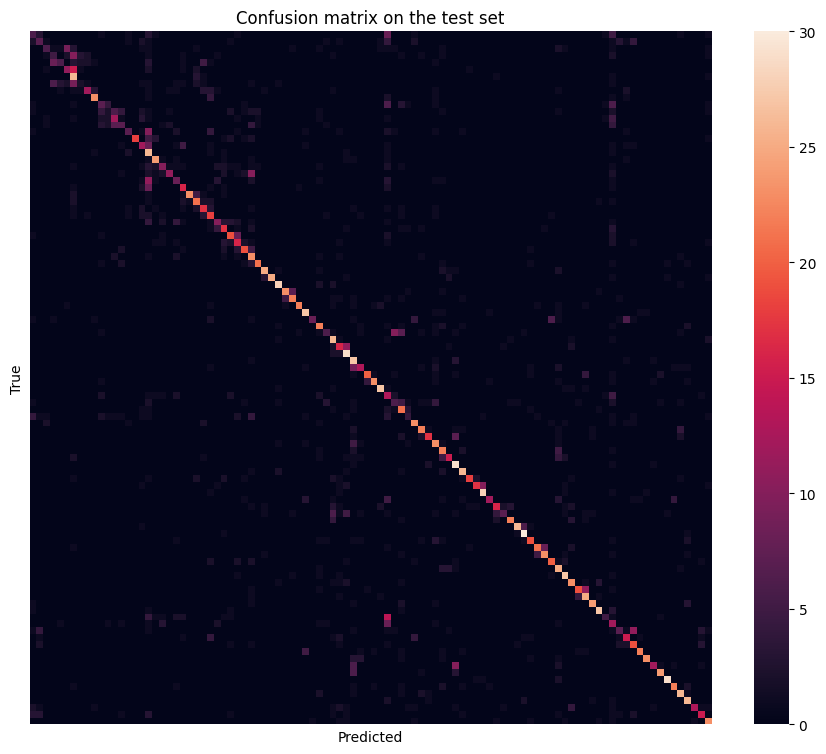

true                         predicted                    count
737-500                      737-600                         15
L-1011                       DC-10                           14
Gulfstream IV                Gulfstream V                    11
A300B4                       767-300                         11
CRJ-700                      CRJ-900                         11
MD-80                        MD-90                           11
E-190                        E-195                           10
C-47                         DC-3                            10
757-200                      767-300                         10
777-300                      A340-600                        10


In [24]:
# accuracy recomputed from the confusion matrix, as a sanity check
print(f"Accuracy from the confusion matrix: {confusion_matrix.diag().sum() / confusion_matrix.sum():.3f}")

plt.figure(figsize=(11, 9))
sn.heatmap(pd.DataFrame(confusion_matrix), cbar=True, xticklabels=False, yticklabels=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix on the test set"); plt.show()

# the variants the model confuses most often
errors = confusion_matrix.clone()
errors.fill_diagonal_(0)
worst = torch.topk(errors.flatten(), 10)
print(f"{'true':28s} {'predicted':28s} {'count':>5s}")
for value, index in zip(worst.values, worst.indices):
    true_class, predicted_class = index // n_classes, index % n_classes
    print(f"{test_dset.classes[true_class]:28s} {test_dset.classes[predicted_class]:28s} {value.item():5d}")